# 05 · Contarlo: el mapa de productos y la historia del proyecto

Este notebook cierra el proyecto. Tiene dos partes:

1. **El mapa de productos**: la red ubica cada producto en un espacio de 128 dimensiones. Con **UMAP** lo aplastamos a 2 dimensiones para poder mirarlo. ¿Qué organizó la red sin que nadie se lo pidiera?
2. **La historia en gráficos**: el recorrido completo del proyecto, de la pregunta a las conclusiones, con los gráficos de los notebooks 00 a 04.

## ¿Qué es UMAP?

Un método para **reducir dimensiones**: toma puntos en un espacio de muchas dimensiones (acá, 128) y los acomoda en 2D tratando de que **los que estaban cerca sigan cerca**. No conserva bien las distancias grandes (que dos grupos estén lejos en el gráfico no dice mucho), pero sí los **vecindarios**: si dos productos quedan pegados, la red los considera parecidos.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import umap

from src.splits import load_splits
from src.evaluate import ItemIndex
from src.two_tower import TwoTowerRecommender

FIG = ROOT / "reports" / "figures"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

s = load_splits()
idx = ItemIndex(s.items)
todo = pd.concat([s.train, s.val_warm, s.val_cold], ignore_index=True)
tt = TwoTowerRecommender(todo, s.users, s.items, idx, weights=ROOT / "models" / "two_tower_final.pt", dim=128, hidden=512)

V = tt.item_vectors().numpy()
items = s.items.reset_index(drop=True).copy()
items["positivos"] = np.bincount(idx.to_pos(todo.product_id), minlength=len(idx))
xy = umap.UMAP(n_neighbors=15, min_dist=0.1, metric="cosine", random_state=42).fit_transform(V)
items["x"], items["y"] = xy[:, 0], xy[:, 1]
print(f"{len(items):,} productos, vectores de {V.shape[1]} dimensiones -> 2D")

2,351 productos, vectores de 128 dimensiones -> 2D


### El mapa, coloreado por categoría

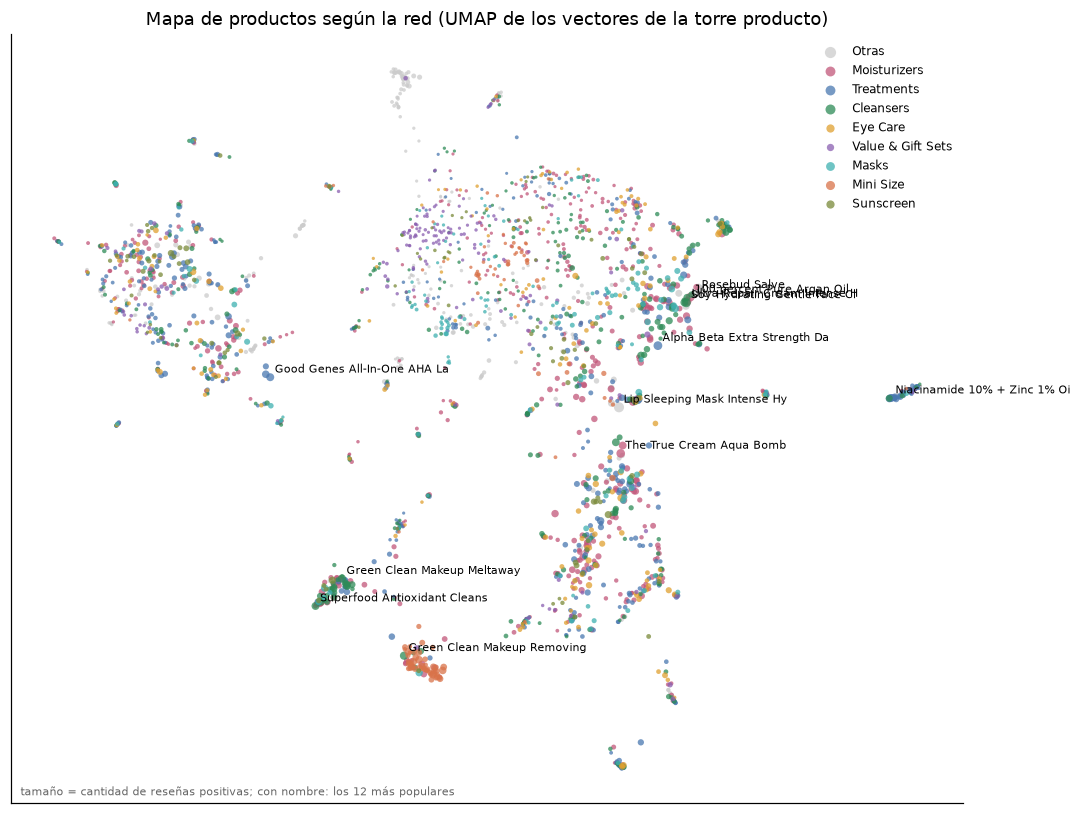

In [2]:
top_cats = items.secondary_category.value_counts().index[:8]
items["categoría"] = items.secondary_category.where(items.secondary_category.isin(top_cats), "Otras")
paleta = dict(zip(list(top_cats) + ["Otras"],
                  ["#c2577a", "#4a78b0", "#2e8b57", "#e0a030", "#8a5fb0", "#3fb0b0", "#d9734a", "#7a8a3a", "#cccccc"]))
tam = 4 + 40 * (items.positivos / items.positivos.max()) ** 0.5

fig, ax = plt.subplots(figsize=(10, 7.5))
for c in ["Otras"] + list(top_cats):
    m = items["categoría"] == c
    ax.scatter(items.x[m], items.y[m], s=tam[m], c=paleta[c], label=c, alpha=0.75, linewidths=0)
for _, p in items.nlargest(12, "positivos").iterrows():
    ax.annotate(p.product_name[:28], (p.x, p.y), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax.set(xticks=[], yticks=[], title="Mapa de productos según la red (UMAP de los vectores de la torre producto)")
ax.legend(fontsize=8, markerscale=1.5, loc="best", frameon=False)
ax.text(0.01, 0.01, "tamaño = cantidad de reseñas positivas; con nombre: los 12 más populares",
        transform=ax.transAxes, fontsize=7, color="#666")
plt.tight_layout()
plt.savefig(FIG / "05_mapa_productos.png", bbox_inches="tight")
plt.show()

**Cómo leerlo:**

- **Los colores (categorías) están bastante mezclados.** Si la red organizara los productos por tipo, veríamos manchas de un solo color: todas las cremas juntas, todos los limpiadores juntos. No pasa.
- **En cambio, aparecen "islas" compactas.** La de la derecha es casi entera de *The Ordinary* (44 de sus 45 productos, de varias categorías) y la isla naranja de abajo son los **tamaños mini** (49 de 70). No todas las islas son de una marca: la de abajo a la izquierda mezcla limpiadores e hidratantes de marcas de gama alta (Tatcha, Sulwhasoo, Dermalogica).
- Los productos más populares (con nombre) quedan en el borde de la nube central, cerca unos de otros: los "favoritos universales" que vimos en el notebook 03.

La tabla de abajo lo confirma con números.

### ¿Qué separa la red? Pureza de los vecindarios

Una forma de medir qué organizó la red: para cada producto, miramos sus 10 vecinos más cercanos **en el espacio original de 128 dimensiones** y contamos qué proporción comparte su categoría, su subcategoría o su marca. Lo comparamos con lo que daría el azar.

In [3]:
Vn = V / np.linalg.norm(V, axis=1, keepdims=True)
sim = Vn @ Vn.T
np.fill_diagonal(sim, -np.inf)
vec = np.argsort(-sim, axis=1)[:, :10]

filas = []
for col, nombre in [("secondary_category", "categoría"), ("tertiary_category", "subcategoría"), ("brand_name", "marca")]:
    v = items[col].astype(str).to_numpy()
    valido = items[col].notna().to_numpy()
    comparte = (v[vec] == v[:, None])[valido].mean()
    frec = items[col].value_counts(normalize=True)
    azar = (frec ** 2).sum()  # probabilidad de que dos productos al azar compartan el valor
    filas.append({"comparten...": nombre, "vecinos de la red": comparte, "al azar": azar, "veces más que el azar": comparte / azar})
pd.DataFrame(filas).set_index("comparten...").style.format({"vecinos de la red": "{:.0%}", "al azar": "{:.0%}", "veces más que el azar": "{:.1f}×"})

,vecinos de la red,al azar,veces más que el azar
comparten...,,,
categoría,32%,14%,2.3×
subcategoría,20%,10%,2.0×
marca,47%,1%,33.6×


**Cómo leerlo:** los vecinos de un producto comparten su **marca** el 47% de las veces, **34 veces más que el azar**. Comparten la categoría solo 2,3 veces más que el azar.

**La red organizó el catálogo por marca, no por tipo de producto.** Tiene sentido con lo que hacen las personas: a quien le gusta un producto de Drunk Elephant le suelen gustar otros de Drunk Elephant (un limpiador, un sérum, una máscara). Arman **rutinas de marca**. Para recomendar, "otro producto de la marca que te gusta" es una apuesta mejor que "otra crema hidratante".

Los ejemplos de abajo lo muestran: los vecinos de la *Protini* de Drunk Elephant son un limpiador, unas gotas y una crema de retinol, todos de Drunk Elephant. La excepción interesante es el tratamiento para acné de Kate Somerville: sus vecinos mezclan su marca con productos **para acné** de Peter Thomas Roth. Ahí la red agrupó por **problema de piel**.

### Productos "intercambiables" según la red

Algunos ejemplos de productos populares y sus vecinos más cercanos:

In [4]:
for j in items.nlargest(60, "positivos").sample(5, random_state=3).index:
    v = vec[j, :4]
    print(f"\n{items.product_name[j]} ({items.brand_name[j]}, {items.tertiary_category[j]}):")
    for k in v:
        print(f"   {sim[j, k]:.2f}  {items.product_name[k][:55]} ({items.brand_name[k]}, {items.tertiary_category[k]})")


EradiKate Acne Treatment (Kate Somerville, Blemish & Acne Treatments):
   0.94  Anti Bac Acne Clearing Lotion (Kate Somerville, Face Serums)
   0.93  Goodbye Acne  Max Complexion Correction Pads (Peter Thomas Roth, Blemish & Acne Treatments)
   0.93  ExfoliKate Cleanser Daily Foaming Wash (Kate Somerville, Face Wash & Cleansers)
   0.93  Therapeutic Sulfur Acne Treatment Mask (Peter Thomas Roth, Face Masks)

Mini Daily Microfoliant Exfoliator (Dermalogica, nan):
   0.57  Mini GOOPGLOW Microderm Instant Glow Exfoliator (goop, nan)
   0.57  Mini GOOPGLOW 15% Glycolic Acid Overnight Glow Peel (goop, nan)
   0.55  Mini Precleanse Cleansing Oil (Dermalogica, nan)
   0.54  Mini The Water Cream (Tatcha, nan)

Vinoperfect Radiance Dark Spot Serum Vitamin C Alternative (Caudalie, Face Serums):
   0.90  Vinosource-Hydra Moisturizing Sorbet (Caudalie, Moisturizers)
   0.90  Grape Water Moisturizing Face Mist (Caudalie, Mists & Essences)
   0.89  Pore Minimizing Instant Detox Mask (Caudalie, Face

---

# La historia del proyecto, en 6 gráficos

### 1 · La pregunta
*Si me decís tu tipo y tono de piel, ¿te puedo recomendar skincare que te vaya a gustar, aunque nunca hayas reseñado nada? ¿Y funciona igual de bien para todos los tonos de piel?*

### 2 · Los datos: el cold start es la norma, y los tonos están muy desbalanceados
El 58% de las personas tiene una sola reseña, y los tonos claros dominan el dataset (notebook 00).

![](../reports/figures/00_resenas_por_persona.png)
![](../reports/figures/00_personas_por_tono.png)

### 3 · La vara: modelos simples, bien ajustados
Antes de la red, ajustamos cuatro baselines (notebook 02). Con historial, el ALS multiplica por 3,6 a la popularidad. Sin historial, el perfil de piel ayuda, pero poco.

![](../reports/figures/02_baselines_recall.png)

### 4 · La red two-tower
Una torre para la persona (perfil + historial) y otra para el producto (marca, categoría, precio, ingredientes, highlights), entrenadas juntas con una softmax sobre todo el catálogo (notebook 03).

![](../reports/figures/03_curvas_entrenamiento.png)

### 5 · Qué aporta cada pieza
Las ablaciones (notebook 04) muestran que cada pieza tiene su escenario: el perfil solo sirve sin historial, el historial es la pieza clave y el contenido de los productos es lo que permite alcanzar al ALS.

![](../reports/figures/04_ablaciones.png)

### 6 · El resultado final, en test
**Sin historial, la red gana** (10,2% contra 8,9% del mejor baseline). **Con historial, empata con el ALS** (15,2% contra 15,0%).

![](../reports/figures/04_test.png)

### Y la pregunta de fairness
No encontramos una brecha en contra de ningún grupo de tono. En cold start, **el perfil le sirve más que a nadie al grupo *oscuro***. Pero encontramos un **sesgo de origen** en los tonos más chicos (*dark*, *porcelain*, *olive*): esas personas reseñan casi solo dos marcas, y la red "acierta" aprendiendo ese artefacto.

![](../reports/figures/04_estabilidad_por_tono.png)

## Lo que me llevo del proyecto

1. **Un buen baseline vale oro.** Sin el ALS bien ajustado, habríamos celebrado una red que, con historial, no gana.
2. **Test existe por una razón.** La ventaja con historial que vimos en validación no se sostuvo en test. Y encontramos un error de protocolo justo porque test daba raro.
3. **Mirar *qué* se recomienda, no solo cuánto se acierta.** La métrica más alta del proyecto (los tonos chicos) resultó ser un sesgo de los datos.
4. **El dato raro suele ser una pista**: el "reloj escondido" de los perfiles incompletos (notebook 02) y las dos marcas de los tonos chicos (notebook 04) aparecieron porque un número no cerraba.

**La demo**: `.venv\Scripts\streamlit run web/app.py`